# Bank Marketing Campaign Effectiveness

Author: Robin Christian Navarro <br>
Date: 11-11-2026

## Exploratory Data Analysis

### Introduction

A Portuguese bank ran telephone campaigns for term deposits. The campaign manager wants to understand how subscription outcomes varied by contact channel, contact frequency, and campaign history before deciding what to test next.

This notebook uses **bank-additional-full.csv** from UCI, with 41,188 observations and 20 inputs plus `y`. The analysis describes associations in the campaign records.

**Source.** [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing) · [Moro, Cortez, and Rita (2014)](https://doi.org/10.1016/j.dss.2014.03.001)

#### Business Questions

1. What was the overall term-deposit subscription rate?
2. How did subscription rates and counts differ by contact channel?
3. How did subscription rates vary with the number of contacts in the current campaign?
4. How did outcomes differ by previous campaign result?
5. Among previously contacted records with known recency, how did time since the previous contact relate to subscription?
6. Did subscription rates differ by weekday of the last contact?
7. Does the contact-count pattern persist within each channel?

---

### Environment Setup

We will import the necessary libraries and load the dataset for analysis.

Pandas - used for data manipulation, cleaning, and analysis.
Seaborn and Matplotlib - used for data visualization and statistical graphics.

Extract the full additional CSV from the UCI download to `data/raw/bank-additional-full.csv`. Run `uv sync --locked` and select the project Python kernel in VS Code.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read the semicolon-delimited dataset
df = pd.read_csv('./data/raw/bank-additional-full.csv', sep=';')

---

### Data Exploration

In [3]:
# Display the first few rows of the dataset
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Display the last few rows of the dataset
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [5]:
# The shape of the dataset
rows, columns = df.shape
print(f"The dataset contains {rows} rows and {columns} columns.")

The dataset contains 41188 rows and 21 columns.


In [6]:
# Information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

---

### Data Cleaning

In [7]:
# Check null values
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [8]:
# Check duplicates
print(f"The dataset contains {df.duplicated().sum()} duplicate rows.")

The dataset contains 12 duplicate rows.


In [9]:
# Remove exact duplicate rows for the main analysis and keep the raw data
df_deduplicated = df.drop_duplicates()
print(f"Records after removing exact duplicates: {len(df_deduplicated):,}")

Records after removing exact duplicates: 41,176


In [10]:
# Give the existing index a label for display
df_clean = df_deduplicated.rename_axis("id")
df_clean.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
id,,,,,,,,,,,,,,,,,,,,,
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [11]:
# Rename the columns name to be more descriptive and consistent
rename = {
          "pdays": "previous_contact_days",
          "poutcome": "previous_campaign_outcome",
          "emp.var.rate": "employment_variation_rate",
          "cons.price.idx": "consumer_price_index",
          "cons.conf.idx": "consumer_confidence_index",
          "euribor3m": "euribor_3_months",
          "nr.employed": "number_of_employees",
          "y": "subscribed_to_term_deposit"}
df_clean = df_clean.rename(columns=rename)
df_clean.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous_contact_days,previous,previous_campaign_outcome,employment_variation_rate,consumer_price_index,consumer_confidence_index,euribor_3_months,number_of_employees,subscribed_to_term_deposit
id,,,,,,,,,,,,,,,,,,,,,
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [12]:
# Clean the "job" column by replacing certain values
df_clean["job"] = df_clean["job"].replace({
    "admin.": "admin",
    "blue-collar": "blue_collar",
    "self-employed": "self_employed",
})
df_clean["job"].unique()

<StringArray>
[    'housemaid',      'services',         'admin',   'blue_collar',
    'technician',       'retired',    'management',    'unemployed',
 'self_employed',       'unknown',  'entrepreneur',       'student']
Length: 12, dtype: str

In [13]:
# Clean the "education" column by replacing certain values
df_clean["education"] = df_clean["education"].replace({
    "basic.4y": "basic_education_4_years",
    "basic.6y": "basic_education_6_years",
    "basic.9y": "basic_education_9_years",
    "high.school": "high_school",
    "professional.course": "professional_course",
    "university.degree": "university_degree",
})
df_clean["education"].unique()

<StringArray>
['basic_education_4_years',             'high_school',
 'basic_education_6_years', 'basic_education_9_years',
     'professional_course',                 'unknown',
       'university_degree',              'illiterate']
Length: 8, dtype: str

In [14]:
# Clean the "month" column by replacing the abbreviated month names with full month names
df_clean["month"] = df_clean["month"].replace({
    "jan": "January",
    "feb": "February",
    "mar": "March",
    "apr": "April",
    "may": "May",
    "jun": "June",
    "jul": "July",
    "aug": "August",
    "sep": "September",
    "oct": "October",
    "nov": "November",
    "dec": "December",
})
df_clean["month"].unique()

<StringArray>
[      'May',      'June',      'July',    'August',   'October',  'November',
  'December',     'March',     'April', 'September']
Length: 10, dtype: str

In [15]:
# Keep the original precision of the quarterly employment indicator
df_clean["number_of_employees"] = pd.to_numeric(df_clean["number_of_employees"], errors="raise")
df_clean["number_of_employees"].unique()

array([5191. , 5228.1, 5195.8, 5176.3, 5099.1, 5076.2, 5017.5, 5023.5,
       5008.7, 4991.6, 4963.6])

---

### Descriptive Statistics



In [16]:
df_clean.describe(include='all')

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous_contact_days,previous,previous_campaign_outcome,employment_variation_rate,consumer_price_index,consumer_confidence_index,euribor_3_months,number_of_employees,subscribed_to_term_deposit
count,41176.00000,41176,41176,41176,41176,41176,41176,41176,41176,41176,41176.000000,41176.000000,41176.000000,41176.000000,41176,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176
unique,NaN,12,4,8,3,3,3,2,10,5,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin,married,university_degree,no,yes,no,cellular,May,thu,NaN,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10419,24921,12164,32577,21571,33938,26135,13767,8618,NaN,NaN,NaN,NaN,35551,NaN,NaN,NaN,NaN,NaN,36537
mean,40.02380,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258.315815,2.567879,962.464810,0.173013,NaN,0.081922,93.575720,-40.502863,3.621293,5167.034870,NaN
std,10.42068,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,259.305321,2.770318,186.937102,0.494964,NaN,1.570883,0.578839,4.627860,1.734437,72.251364,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.000000,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.000000,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,319.000000,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


---

### Explanatory Data Analysis



#### 1. What was the overall term-deposit subscription rate?

In [17]:
subscription_counts = df_clean["subscribed_to_term_deposit"].value_counts().reindex(
    ["no", "yes"], fill_value=0
)

subscription_percentage = subscription_counts / subscription_counts.sum() * 100

subscription_summary = pd.DataFrame({
    "Count": subscription_counts,
    "Percentage": subscription_percentage
})

subscription_summary.index = pd.Index(
    ["Not Subscribed", "Subscribed"],
    name="Term Deposit Status"
)

subscription_summary.round(1)

,Count,Percentage
Term Deposit Status,,
Not Subscribed,36537,88.7
Subscribed,4639,11.3


**Result.** Of 41,176 records after removing 12 exact duplicate rows, 4,639 subscribed (11.3%) and 36,537 did not (88.7%). The raw file also rounds to 11.3%. With no client ID, this is a record-level baseline and the duplicate policy is an assumption.

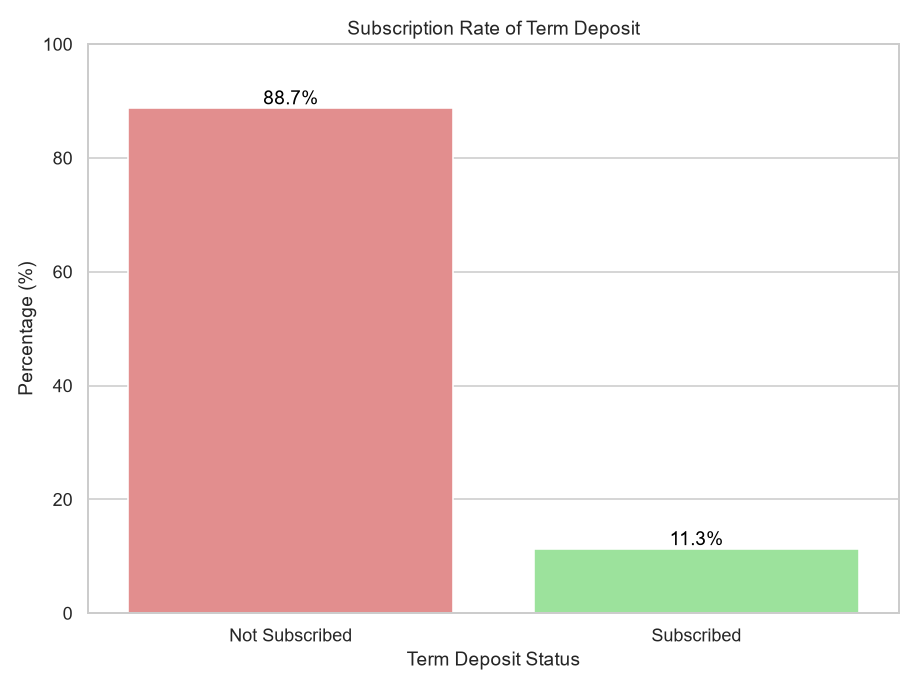

In [18]:
sns.set_theme(style="whitegrid")

figure, axis = plt.subplots(figsize=(8, 6))

subscription_graph = sns.barplot(
  data=subscription_summary.reset_index(),
  x="Term Deposit Status",
  y="Percentage",
  hue="Term Deposit Status",
  palette={"Not Subscribed": "lightcoral", "Subscribed": "lightgreen"},
  legend=False,
  ax=axis
)

subscription_graph.set(
  title="Subscription Rate of Term Deposit",
  xlabel="Term Deposit Status",
  ylabel="Percentage (%)",
  ylim=(0, 100)
)
axis.bar_label(subscription_graph.containers[0], fmt='%.1f%%', label_type='edge', fontsize=12, color='black')
axis.bar_label(subscription_graph.containers[1], fmt='%.1f%%', label_type='edge', fontsize=12, color='black')


figure.tight_layout()
plt.show()

#### 2. How did subscription rates and counts differ by contact channel?

In [19]:
contact_data = df_clean.loc[
    df_clean["contact"].notna()
    & df_clean["subscribed_to_term_deposit"].isin(["yes", "no"]),
    ["contact", "subscribed_to_term_deposit"]
].copy()

contact_data["Subscribed"] = contact_data["subscribed_to_term_deposit"].eq("yes")
subscription_by_contact_summary = contact_data.groupby("contact")["Subscribed"].agg(
    Record_Count="size",
    Subscription_Count="sum"
)
subscription_by_contact_summary["Subscription_Percentage"] = (
    subscription_by_contact_summary["Subscription_Count"]
    / subscription_by_contact_summary["Record_Count"] * 100
)
subscription_by_contact_summary = subscription_by_contact_summary.sort_values(
    by="Subscription_Percentage", ascending=False
)
subscription_by_contact_summary.round(1)

,Record_Count,Subscription_Count,Subscription_Percentage
contact,,,
cellular,26135,3852,14.7
telephone,15041,787,5.2


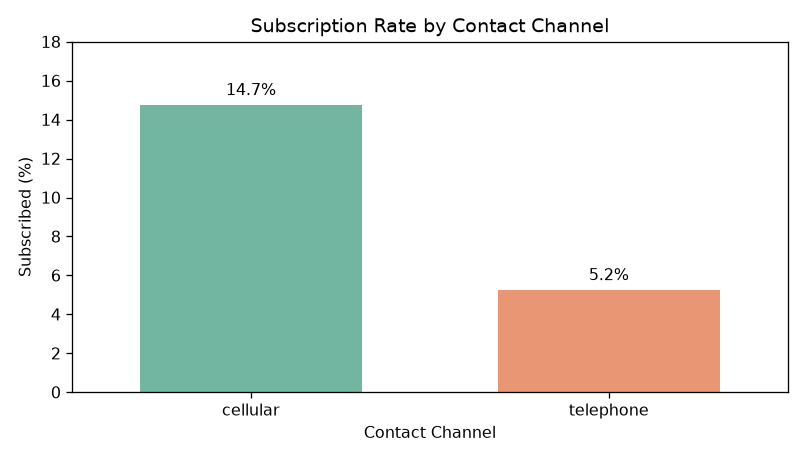

In [20]:
# Plot subscription rates by contact channel
figure, axis = plt.subplots(figsize=(7, 4))
sns.barplot(data=subscription_by_contact_summary.reset_index(), x="contact",
            y="Subscription_Percentage", hue="contact",
            palette="Set2", legend=False, dodge=False, width=0.62, ax=axis)
axis.set(title="Subscription Rate by Contact Channel", xlabel="Contact Channel",
         ylabel="Subscribed (%)", ylim=(0, 18))
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=4)
figure.tight_layout()
plt.show()

**Result.** Cellular had 3,852 subscriptions from 26,135 records (14.7%). Telephone had 787 from 15,041 (5.2%). The gap is 9.5 percentage points. The channel comparison may reflect who was contacted and when, so it is a candidate for a controlled test.

#### 3. How did subscription rates vary with the number of contacts in the current campaign?

In [21]:
# Group records by number of contacts in the current campaign
df_clean["Subscribed"] = df_clean["subscribed_to_term_deposit"].eq("yes")
assert df_clean["subscribed_to_term_deposit"].isin(["yes", "no"]).all()
assert df_clean["campaign"].ge(1).all()
df_clean["Contact_Count_Group"] = pd.cut(
    df_clean["campaign"], bins=[0, 1, 2, 4, float("inf")],
    labels=["1", "2", "3–4", "5+"]
)

subscription_by_attempt_summary = df_clean.groupby(
    "Contact_Count_Group", observed=True
)["Subscribed"].agg(Record_Count="size", Subscription_Count="sum")
subscription_by_attempt_summary["Subscription_Percentage"] = (
    subscription_by_attempt_summary["Subscription_Count"]
    / subscription_by_attempt_summary["Record_Count"] * 100
)
subscription_by_attempt_summary.round(1)

,Record_Count,Subscription_Count,Subscription_Percentage
Contact_Count_Group,,,
1,17634,2299,13.0
2,10568,1211,11.5
3–4,7990,823,10.3
5+,4984,306,6.1


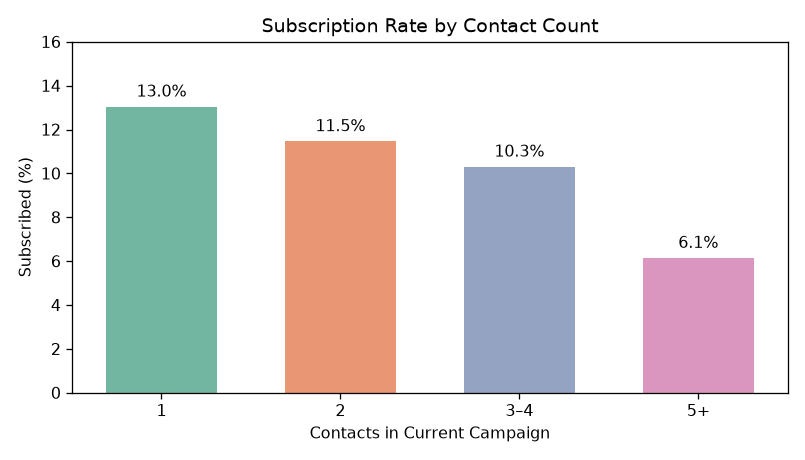

In [22]:
# Plot subscription rates by number of contacts
figure, axis = plt.subplots(figsize=(7, 4))
sns.barplot(data=subscription_by_attempt_summary.reset_index(), x="Contact_Count_Group",
            y="Subscription_Percentage", hue="Contact_Count_Group",
            palette="Set2", legend=False, dodge=False, width=0.62, ax=axis)
axis.set(title="Subscription Rate by Contact Count", xlabel="Contacts in Current Campaign",
         ylabel="Subscribed (%)", ylim=(0, 16))
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=4)
figure.tight_layout()
plt.show()

**Result.** Subscription rates were 13.0% after one recorded contact (2,299 of 17,634), 11.5% after two, 10.3% after three to four, and 6.1% after five or more (306 of 4,984). Records with more contacts may represent harder-to-convert clients, and subscriptions may end outreach.

#### 4. How did outcomes differ by previous campaign result?

In [23]:
# Compare subscription outcomes by previous campaign result
previous_outcome_summary = df_clean.groupby("previous_campaign_outcome")["Subscribed"].agg(
    Record_Count="size",
    Subscription_Count="sum"
)
previous_outcome_summary["Subscription_Percentage"] = (
    previous_outcome_summary["Subscription_Count"] / previous_outcome_summary["Record_Count"] * 100
)
previous_outcome_summary.sort_values("Subscription_Percentage", ascending=False).round(1)

,Record_Count,Subscription_Count,Subscription_Percentage
previous_campaign_outcome,,,
success,1373,894,65.1
failure,4252,605,14.2
nonexistent,35551,3140,8.8


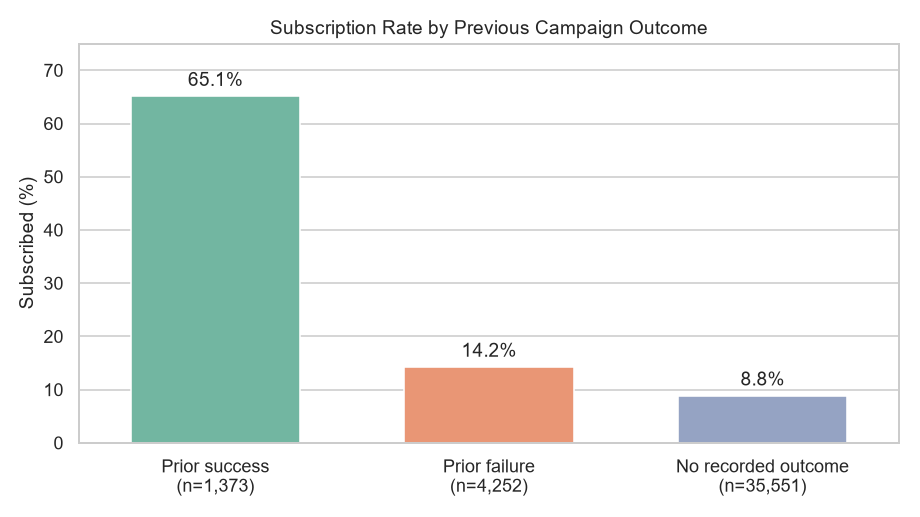

In [ ]:
# Compare subscription rates by previous campaign outcome
outcome_plot = previous_outcome_summary.sort_values("Subscription_Percentage", ascending=False).reset_index()
outcome_labels = {"success": "Prior success", "failure": "Prior failure", "nonexistent": "No recorded outcome"}
outcome_plot["Outcome"] = outcome_plot["previous_campaign_outcome"].map(outcome_labels)
outcome_plot["Group"] = outcome_plot["Outcome"] + outcome_plot["Record_Count"].map(lambda n: f"\n(n={n:,})")

figure, axis = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=outcome_plot, x="Group", y="Subscription_Percentage",
            hue="Group", palette="Set2", legend=False, dodge=False, width=0.62, ax=axis)
axis.set(title="Subscription Rate by Previous Campaign Outcome",
         xlabel="", ylabel="Subscribed (%)", ylim=(0, 75))
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=4)
figure.tight_layout()
plt.show()

**Result.** Prior success was associated with 65.1% subscription (894 of 1,373), compared with 14.2% after prior failure (605 of 4,252) and 8.8% with no recorded previous outcome (3,140 of 35,551). Prior outcome is a useful variable for balancing groups in a future experiment.

#### 5. Among previously contacted records with known recency, how did time since the previous contact relate to subscription?

In [24]:
# Use records with a previous contact and a known recency value
has_recency = df_clean["previous_contact_days"].between(0, 998)
has_previous = df_clean["previous"].gt(0)
print(f"Records with previous contacts and a 999 recency code: {(has_previous & df_clean['previous_contact_days'].eq(999)).sum():,}")
recency_data = df_clean.loc[has_previous & has_recency].copy()
recency_data["Recency_Group"] = pd.cut(
    recency_data["previous_contact_days"], bins=[-1, 3, 7, float("inf")],
    labels=["0–3 days", "4–7 days", "8+ days"]
)
subscription_by_recency_summary = recency_data.groupby(
    "Recency_Group", observed=True
)["Subscribed"].agg(Record_Count="size", Subscription_Count="sum")
subscription_by_recency_summary["Subscription_Percentage"] = (
    subscription_by_recency_summary["Subscription_Count"]
    / subscription_by_recency_summary["Record_Count"] * 100
)
subscription_by_recency_summary.round(1)

Records with previous contacts and a 999 recency code: 4,110


,Record_Count,Subscription_Count,Subscription_Percentage
Recency_Group,,,
0–3 days,541,353,65.2
4–7 days,636,421,66.2
8+ days,338,193,57.1


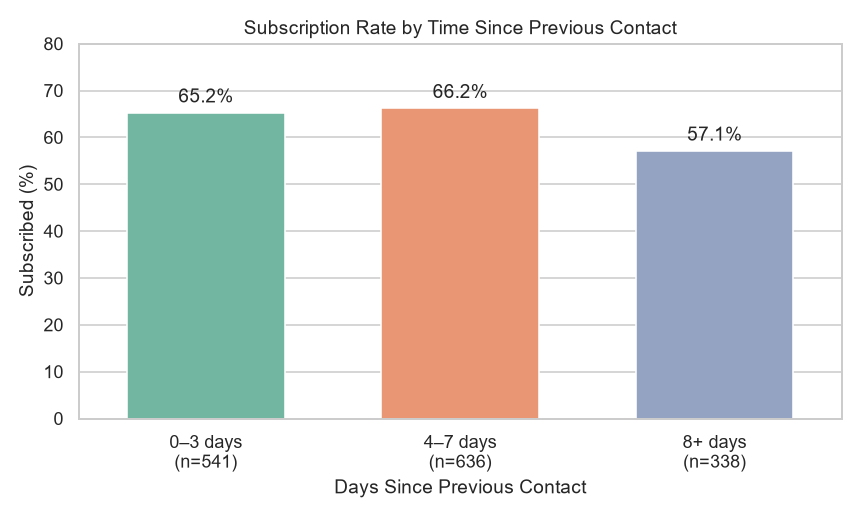

In [ ]:
# Plot recency bands for records with a known time since previous contact
recency_plot = subscription_by_recency_summary.reset_index()
recency_plot["Group"] = recency_plot["Recency_Group"].astype(str) + recency_plot["Record_Count"].map(lambda n: f"\n(n={n:,})")

figure, axis = plt.subplots(figsize=(7.5, 4.5))
sns.barplot(data=recency_plot, x="Group", y="Subscription_Percentage",
            hue="Group", palette="Set2", legend=False, dodge=False, width=0.62, ax=axis)
axis.set(title="Subscription Rate by Time Since Previous Contact",
         xlabel="Days Since Previous Contact", ylabel="Subscribed (%)", ylim=(0, 80))
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=4)
figure.tight_layout()
plt.show()

**Result.** Among the 1,515 records with known recency and prior contact, the subscription rates were 65.2% at 0–3 days (353 of 541), 66.2% at 4–7 days (421 of 636), and 57.1% at 8+ days (193 of 338). The CSV contains 4,110 records with positive previous contact counts and the 999 recency code. Excluding them limits this result to the known-recency subset.

#### 6. Did subscription rates differ by weekday of the last contact?

In [25]:
# Compare weekdays in calendar order
weekdays = ["mon", "tue", "wed", "thu", "fri"]
weekday_summary = df_clean.groupby("day_of_week")["Subscribed"].agg(
    Record_Count="size", Subscription_Count="sum"
).reindex(weekdays)
weekday_summary["Subscription_Percentage"] = (
    weekday_summary["Subscription_Count"] / weekday_summary["Record_Count"] * 100
)

# Compare the three months with the most records
largest_months = df_clean["month"].value_counts().head(3).index
month_data = df_clean.loc[df_clean["month"].isin(largest_months)]
month_weekday_summary = month_data.groupby(["month", "day_of_week"])["Subscribed"].agg(
    Record_Count="size", Subscription_Count="sum"
)
month_weekday_summary["Subscription_Percentage"] = (
    month_weekday_summary["Subscription_Count"] / month_weekday_summary["Record_Count"] * 100
)
display(weekday_summary.round(1))
month_weekday_summary.round(1)

,Record_Count,Subscription_Count,Subscription_Percentage
day_of_week,,,
mon,8512,847,10.0
tue,8086,953,11.8
wed,8134,949,11.7
thu,8618,1044,12.1
fri,7826,846,10.8


Record_Count  Subscription_Count  Subscription_Percentage
month  day_of_week                                                           
August fri                  1070                 122                     11.4
       mon                  1221                 107                      8.8
       thu                  1347                 131                      9.7
       tue                  1295                 148                     11.4
       wed                  1243                 147                     11.8
July   fri                  1012                 118                     11.7
       mon                  1515                 120                      7.9
       thu                  1668                 142                      8.5
       tue                  1517                 133                      8.8
       wed                  1457                 135                      9.3
May    fri                  2857                 199                      7.0
       mon                  2642                 191                      7.2
       thu                  2536                 161                      6.3
       tue                  2809                 149                      5.3
       wed                  2923                 186                      6.4

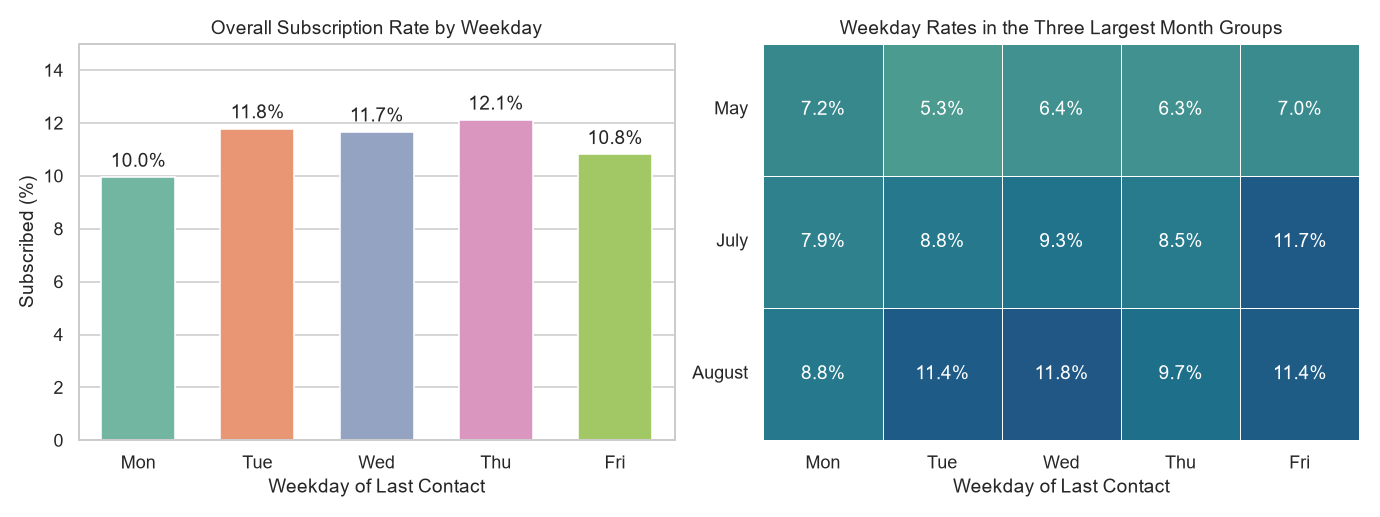

In [ ]:
# Compare weekday rates overall and within the three largest month groups
weekday_plot = weekday_summary.rename_axis("Weekday").reset_index()
weekday_plot["Weekday"] = weekday_plot["Weekday"].str.title()
weekday_by_month = month_weekday_summary["Subscription_Percentage"].unstack("day_of_week")
weekday_by_month = weekday_by_month.reindex(index=largest_months, columns=weekdays)
weekday_by_month.columns = weekday_by_month.columns.str.title()

figure, (axis, month_axis) = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=weekday_plot, x="Weekday", y="Subscription_Percentage",
            hue="Weekday", palette="Set2", legend=False, dodge=False, width=0.62, ax=axis)
axis.set(title="Overall Subscription Rate by Weekday",
         xlabel="Weekday of Last Contact", ylabel="Subscribed (%)", ylim=(0, 15))
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=4)

sns.heatmap(weekday_by_month, annot=weekday_by_month.map(lambda rate: f"{rate:.1f}%"),
            fmt="", cmap="crest", vmin=0, vmax=15, cbar=False, linewidths=0.6, ax=month_axis)
month_axis.set(title="Weekday Rates in the Three Largest Month Groups",
               xlabel="Weekday of Last Contact", ylabel="")
month_axis.tick_params(axis="y", labelrotation=0)
figure.tight_layout()
plt.show()

**Result.** Thursday led overall at 12.1% (1,044 of 8,618) and Monday had the lowest rate at 10.0% (847 of 8,512). In the three largest month groups, Monday led in May, Friday in July, and Wednesday in August. The overall weekday pattern is too dependent on the month mix to justify rescheduling calls.

#### 7. Does the contact-count pattern persist within each channel?

In [26]:
# Compare the same contact-count groups within each channel
channel_attempt_summary = df_clean.groupby(
    ["contact", "Contact_Count_Group"], observed=True
)["Subscribed"].agg(Record_Count="size", Subscription_Count="sum")
channel_attempt_summary["Subscription_Percentage"] = (
    channel_attempt_summary["Subscription_Count"]
    / channel_attempt_summary["Record_Count"] * 100
)
channel_attempt_summary.round(1)

Record_Count  ...  Subscription_Percentage
contact   Contact_Count_Group                ...                         
cellular  1                           11754  ...                     16.6
          2                            6675  ...                     15.3
          3–4                          4886  ...                     13.7
          5+                           2820  ...                      7.7
telephone 1                            5880  ...                      6.0
          2                            3893  ...                      4.9
          3–4                          3104  ...                      5.0
          5+                           2164  ...                      4.1

[8 rows x 3 columns]

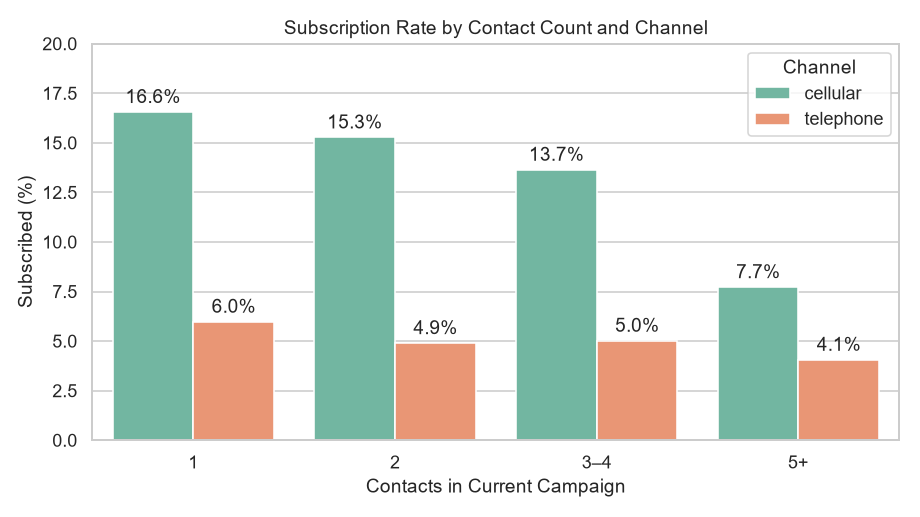

In [27]:
# Plot contact-count patterns by channel
figure, axis = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=channel_attempt_summary.reset_index(), x="Contact_Count_Group",
            y="Subscription_Percentage", hue="contact", palette="Set2", ax=axis)
axis.set(title="Subscription Rate by Contact Count and Channel",
         xlabel="Contacts in Current Campaign", ylabel="Subscribed (%)", ylim=(0, 20))
axis.legend(title="Channel")
for bars in axis.containers:
    axis.bar_label(bars, fmt="%.1f%%", padding=3)
figure.tight_layout()
plt.show()

**Result.** For cellular, the rate fell from 16.6% after one contact (1,947 of 11,754) to 7.7% after five or more (218 of 2,820). For telephone, it fell from 6.0% (352 of 5,880) to 4.1% (88 of 2,164), with a slight rise between two and three to four contacts. Both channels had lower observed rates at five or more contacts.

---

### Conclusion

**What the data shows.** The record-level subscription rate was 11.3%. Cellular and prior campaign success were associated with higher subscription proportions. Five or more contacts were associated with lower proportions within both channels.

**Limitations.** Channel, timing and contact counts were observed rather than assigned. Clients who subscribed may have stopped receiving calls. The file lacks a client ID, so distinct-client counts and exact duplicate identities remain uncertain. The inconsistent 999 recency codes limit recency analysis. Call duration is measured after contact and was excluded from recommendations for decisions made before contact.